# 6. 1D Grating with Two Interleaved Inclusions: Unit-Cell Symmetry Breaking

## Physical Motivation & Learning Objectives
By placing two different dielectric inclusions within a single 1D unit cell, we break spatial inversion symmetry, allowing coupling to asymmetric modes. In this tutorial:
1. We define unit cells with multiple inclusions (`diameter1`, `diameter2`, `inclusion_a`, `inclusion_b`).
2. We simulate asymmetric diffraction order excitation and resonance splitting.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Grating Setup: Two Interleaved Inclusions


In [2]:
wavelengths = np.linspace(700, 1100, 12)
period = 760.0  # nm

light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), world_1d=True, loss=False)

grating = objects.NanoStruct(
    '1D_array', period,
    diameter1=int(round(0.25 * period)),
    diameter2=int(round(0.35 * period)),
    small_space=int(round(0.15 * period)),
    height_nm=300.0,
    background=materials.Material(1.45),
    inclusion_a=materials.Material(3.5),
    inclusion_b=materials.Material(2.5),
    loss=True, lc_bkg=0.01, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light, num_BMs=20)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


## Transmission and Reflection Spectra


<ipython-input-1-5c183317db48>:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


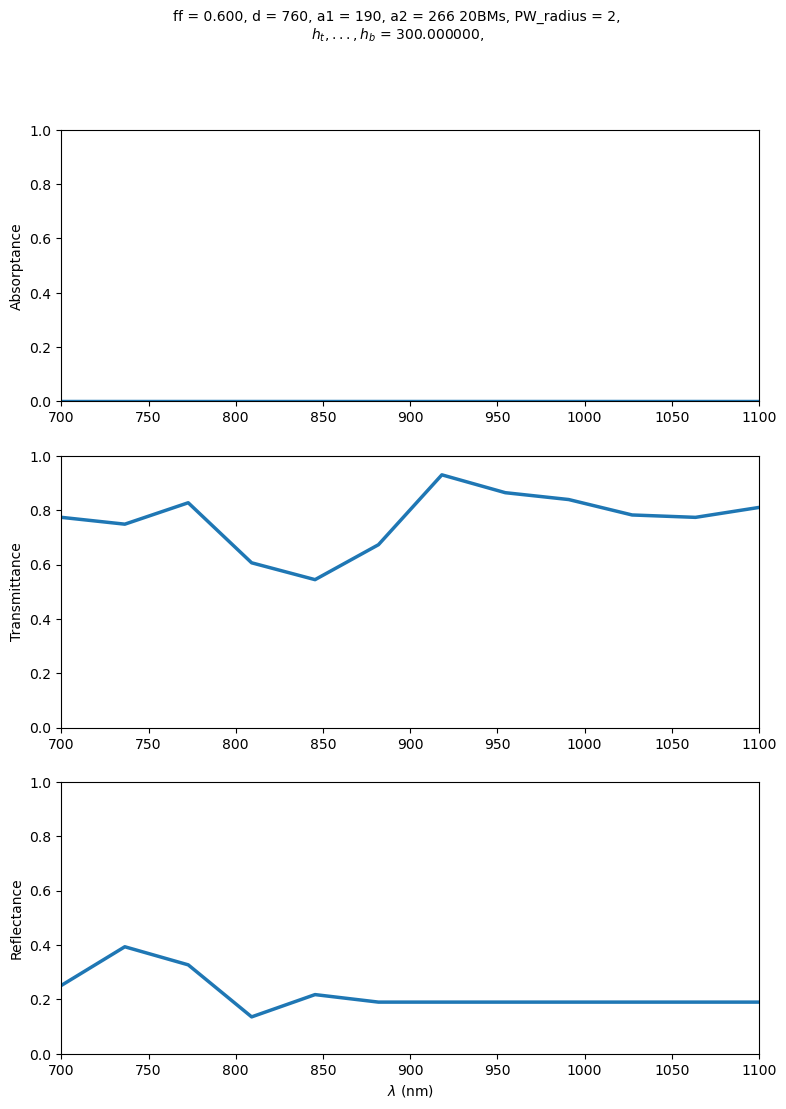

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
The introduction of two distinct inclusions splits the simple 1-element grating modes, producing multi-resonance transmission profiles and asymmetric diffraction patterns.
